# 06 - Comparison charts

Mirrors `notebooks_withseed/05_plot_comparisons`: fine-tuning accuracy by depth with bootstrap
intervals, against reference lines for the sensor-level baselines.

In [9]:
import os, sys, json
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import warnings; warnings.filterwarnings('ignore')
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
OSF, OUT = '../data/preprocessed', '../results_parcel'
MODEL, SUFFIX = 'base', 'cortical'
cv = StratifiedKFold(5, shuffle=True, random_state=123)

labels = np.load(f'{OUT}/parcel_labels_{SUFFIX}.npy')
FROZEN_REF, HANDCRAFT_REF = 0.831, 0.872     # sensor-level OSF references

ft = f'{OUT}/finetune_combined_{MODEL}.pt'
assert os.path.exists(ft), 'run notebook 04 first'
d  = torch.load(ft, map_location='cpu', weights_only=False)
cvr, y_all = d['cv'], d['labels']
print('configs:', sorted(cvr.keys()))

configs: [8, 9, 10]


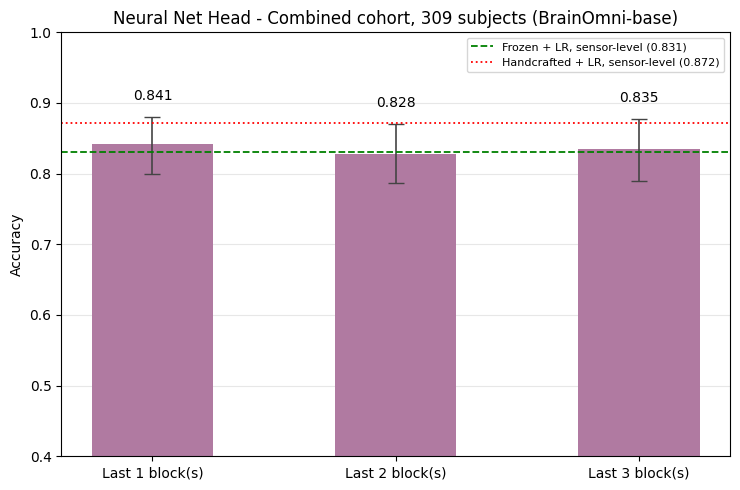

saved parcel_comparison_nn_base.png


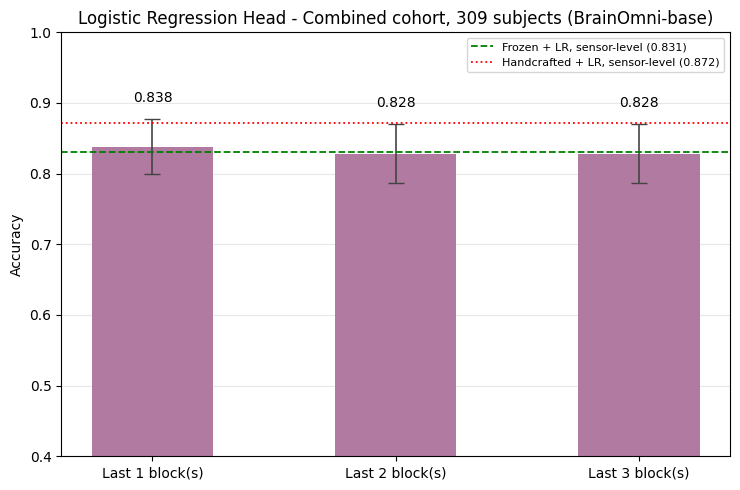

saved parcel_comparison_lr_base.png


In [10]:
def boot_ci(pred, y, nb=2000, seed=123):
    rng = np.random.default_rng(seed); idx = np.arange(len(y)); v = []
    for _ in range(nb):
        b = rng.choice(idx, len(y), replace=True); v.append(accuracy_score(y[b], pred[b]))
    lo, hi = np.percentile(v, [2.5, 97.5])
    return accuracy_score(y, pred), lo, hi

nfs = sorted(cvr.keys(), reverse=True)
for head, key in [('Neural Net Head', 'nn_pred'), ('Logistic Regression Head', 'lr_pred')]:
    accs, elo, ehi = [], [], []
    for nf in nfs:
        a, lo, hi = boot_ci(cvr[nf][key], y_all); accs.append(a); elo.append(a-lo); ehi.append(hi-a)
    x = np.arange(len(nfs))
    fig, ax = plt.subplots(figsize=(max(6, 2.5*len(nfs)), 5))
    b = ax.bar(x, accs, 0.5, yerr=[elo, ehi], capsize=6, color='#B07AA1',
               error_kw=dict(lw=1.2, ecolor='#444'))
    ax.bar_label(b, fmt='%.3f', padding=10, fontsize=10)
    ax.axhline(FROZEN_REF,    color='green', ls='--', lw=1.3, label='Frozen + LR, sensor-level (0.831)')
    ax.axhline(HANDCRAFT_REF, color='red',   ls=':',  lw=1.3, label='Handcrafted + LR, sensor-level (0.872)')
    ax.set_xticks(x); ax.set_xticklabels([f'Last {11-nf} block(s)' for nf in nfs])
    ax.set_ylabel('Accuracy'); ax.set_ylim(0.4, 1.0)
    ax.set_title(f'{head} - Combined cohort, {len(y_all)} subjects (BrainOmni-{MODEL})')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    fname = f'parcel_comparison_{"nn" if key=="nn_pred" else "lr"}_{MODEL}.png'
    plt.tight_layout(); plt.savefig(f'{OUT}/{fname}', dpi=150); plt.show()
    print('saved', fname)